# Mental Health Text Classification — Model Evaluation

## Objective

This notebook develops and evaluates a machine-learning model for classifying
mental-health-related text into four categories:

- Anxiety
- Depression
- Normal
- Suicidal

The project uses TF-IDF feature extraction and Logistic Regression.

Model configurations are compared using a validation set. The final selected
model is then trained on the complete training dataset and evaluated once on
the held-out balanced test dataset.

The primary evaluation metric is **Macro F1**, because it gives equal
importance to all four classes.

## 1. Import Libraries

The notebook uses pandas for data handling, scikit-learn for feature
extraction, model training and evaluation, scipy for combining sparse
feature matrices, and matplotlib for visualizations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import hstack

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Dataset

The dataset is loaded directly from Hugging Face.

The original training dataset is used for model development and validation.
The balanced test dataset is kept separate and is used only for the final
evaluation.

In [2]:
BASE_URL = (
    "https://huggingface.co/datasets/"
    "ourafla/Mental-Health_Text-Classification_Dataset/resolve/main/"
)

TRAIN_FILE = "mental_heath_unbanlanced.csv"
TEST_FILE = "mental_health_combined_test.csv"

train_url = BASE_URL + TRAIN_FILE
test_url = BASE_URL + TEST_FILE

train_df = pd.read_csv(train_url)
test_df = pd.read_csv(test_url)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

Training shape: (49612, 3)
Test shape: (992, 2)


## 3. Prepare Features and Labels

The `text` column contains the input text and the `status` column contains
the target class.

Missing text values are replaced with empty strings and converted to strings.

In [3]:
BASE_URL = (
    "https://huggingface.co/datasets/"
    "ourafla/Mental-Health_Text-Classification_Dataset/resolve/main/"
)

TRAIN_FILE = "mental_heath_unbanlanced.csv"
TEST_FILE = "mental_health_combined_test.csv"

train_url = BASE_URL + TRAIN_FILE
test_url = BASE_URL + TEST_FILE

train_df = pd.read_csv(train_url)
test_df = pd.read_csv(test_url)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

Training shape: (49612, 3)
Test shape: (992, 2)


## 3. Prepare Features and Labels

The `text` column contains the input text and the `status` column contains
the target class.

Missing text values are replaced with empty strings and converted to strings.

In [4]:
X_train = train_df["text"].fillna("").astype(str)
y_train = train_df["status"]

X_test = test_df["text"].fillna("").astype(str)
y_test = test_df["status"]

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Classes:", sorted(y_train.unique()))

Training samples: 49612
Test samples: 992
Classes: ['Anxiety', 'Depression', 'Normal', 'Suicidal']


## 4. Create Training and Validation Sets

The original training data is divided into:

- 80% training data
- 20% validation data

The validation set is used to compare model configurations and tune
hyperparameters.

The held-out test set is not used during model selection.

In [5]:
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train_part))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

Training samples: 39689
Validation samples: 9923
Test samples: 992


## 5. Compare TF-IDF Configurations

Several word-level TF-IDF configurations are evaluated using the same
Logistic Regression classifier.

Macro F1 is used to determine the best configuration.

In [6]:
configs = [
    {
        "name": "Baseline",
        "max_features": 10000,
        "ngram_range": (1, 2),
        "sublinear_tf": False
    },
    {
        "name": "TFIDF 20K",
        "max_features": 20000,
        "ngram_range": (1, 2),
        "sublinear_tf": True
    },
    {
        "name": "TFIDF 30K",
        "max_features": 30000,
        "ngram_range": (1, 2),
        "sublinear_tf": True
    },
    {
        "name": "TFIDF 30K 1-3grams",
        "max_features": 30000,
        "ngram_range": (1, 3),
        "sublinear_tf": True
    },
    {
        "name": "TFIDF 50K 1-3grams",
        "max_features": 50000,
        "ngram_range": (1, 3),
        "sublinear_tf": True
    }
]

validation_results = []

for config in configs:

    vectorizer = TfidfVectorizer(
        max_features=config["max_features"],
        ngram_range=config["ngram_range"],
        sublinear_tf=config["sublinear_tf"]
    )

    X_train_vec = vectorizer.fit_transform(X_train_part)
    X_val_vec = vectorizer.transform(X_val)

    model = LogisticRegression(
        C=1.0,
        max_iter=2000
    )

    model.fit(X_train_vec, y_train_part)

    val_pred = model.predict(X_val_vec)

    validation_results.append({
        "Configuration": config["name"],
        "Accuracy": accuracy_score(y_val, val_pred),
        "Macro F1": f1_score(
            y_val,
            val_pred,
            average="macro"
        ),
        "max_features": config["max_features"],
        "ngram_range": config["ngram_range"],
        "sublinear_tf": config["sublinear_tf"]
    })

validation_results_df = (
    pd.DataFrame(validation_results)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(
    validation_results_df[
        ["Configuration", "Accuracy", "Macro F1"]
    ]
)

,Configuration,Accuracy,Macro F1
0,TFIDF 30K 1-3grams,0.795526,0.778014
1,TFIDF 20K,0.795324,0.777888
2,TFIDF 30K,0.793107,0.775867
3,TFIDF 50K 1-3grams,0.792200,0.774307
4,Baseline,0.789681,0.771279


In [7]:
# Select the best TF-IDF configuration automatically
best_tfidf = validation_results_df.iloc[0]

print("Best TF-IDF configuration:")
print("Configuration:", best_tfidf["Configuration"])
print("Max features:", best_tfidf["max_features"])
print("N-gram range:", best_tfidf["ngram_range"])
print("Sublinear TF:", best_tfidf["sublinear_tf"])
print(f"Validation Accuracy: {best_tfidf['Accuracy']:.4f}")
print(f"Validation Macro F1: {best_tfidf['Macro F1']:.4f}")

Best TF-IDF configuration:
Configuration: TFIDF 30K 1-3grams
Max features: 30000
N-gram range: (1, 3)
Sublinear TF: True
Validation Accuracy: 0.7955
Validation Macro F1: 0.7780


## 6. Tune Logistic Regression C

After selecting the best TF-IDF configuration, different values of the
Logistic Regression regularization parameter `C` are evaluated.

The value with the highest validation Macro F1 is selected.

In [8]:
C_values = [0.1, 0.5, 1, 2, 5, 10]

best_vectorizer = TfidfVectorizer(
    max_features=int(best_tfidf["max_features"]),
    ngram_range=best_tfidf["ngram_range"],
    sublinear_tf=best_tfidf["sublinear_tf"]
)

X_train_vec = best_vectorizer.fit_transform(X_train_part)
X_val_vec = best_vectorizer.transform(X_val)

C_results = []

for C in C_values:

    model = LogisticRegression(
        C=C,
        max_iter=2000
    )

    model.fit(X_train_vec, y_train_part)

    val_pred = model.predict(X_val_vec)

    C_results.append({
        "C": C,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Macro F1": f1_score(
            y_val,
            val_pred,
            average="macro"
        )
    })

C_results_df = (
    pd.DataFrame(C_results)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(C_results_df)

,C,Accuracy,Macro F1
0,2.0,0.795626,0.779512
1,1.0,0.795526,0.778014
2,5.0,0.793510,0.777922
3,10.0,0.787363,0.772458
4,0.5,0.786556,0.765880
5,0.1,0.748060,0.709015


## 7. Select the Best C Value

The C value with the highest validation Macro F1 is selected automatically.

In [9]:
best_C = C_results_df.iloc[0]["C"]

print("Best C:", best_C)
print(f"Validation Accuracy: {C_results_df.iloc[0]['Accuracy']:.4f}")
print(f"Validation Macro F1: {C_results_df.iloc[0]['Macro F1']:.4f}")

Best C: 2.0
Validation Accuracy: 0.7956
Validation Macro F1: 0.7795


## 8. C Value Comparison

The following chart shows how Logistic Regression performance changes as the
regularization parameter C is varied.

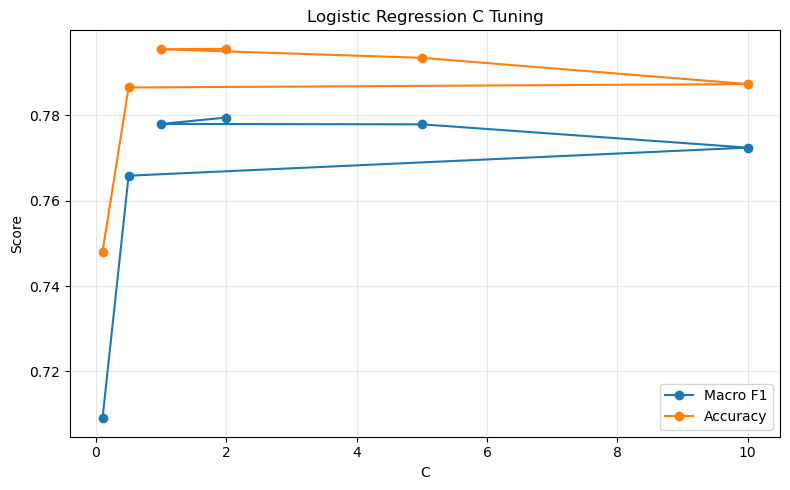

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    C_results_df["C"],
    C_results_df["Macro F1"],
    marker="o",
    label="Macro F1"
)

plt.plot(
    C_results_df["C"],
    C_results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.xlabel("C")
plt.ylabel("Score")
plt.title("Logistic Regression C Tuning")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Evaluate Class Weighting

Because the original training data is imbalanced, class weighting is also
tested.

The experiment compares the default setting with `class_weight="balanced"`.

In [11]:
class_weights = [None, "balanced"]

weight_results = []

for weight in class_weights:

    model = LogisticRegression(
        C=best_C,
        class_weight=weight,
        max_iter=2000
    )

    model.fit(X_train_vec, y_train_part)

    val_pred = model.predict(X_val_vec)

    weight_results.append({
        "Class Weight": str(weight),
        "Accuracy": accuracy_score(y_val, val_pred),
        "Macro F1": f1_score(
            y_val,
            val_pred,
            average="macro"
        )
    })

weight_results_df = (
    pd.DataFrame(weight_results)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(weight_results_df)

,Class Weight,Accuracy,Macro F1
0,balanced,0.797440,0.783034
1,None,0.795626,0.779512


## 10. Add Character-Level TF-IDF Features

Word-level TF-IDF captures complete words and short word sequences.

Character-level TF-IDF can capture useful subword patterns, spelling
variations, and partial word patterns.

The two feature representations are combined and evaluated using the
validation set.

In [12]:
# Word-level TF-IDF
word_tfidf = TfidfVectorizer(
    max_features=int(best_tfidf["max_features"]),
    ngram_range=best_tfidf["ngram_range"],
    sublinear_tf=best_tfidf["sublinear_tf"]
)

X_train_word = word_tfidf.fit_transform(X_train_part)
X_val_word = word_tfidf.transform(X_val)

# Character-level TF-IDF
char_tfidf = TfidfVectorizer(
    analyzer="char",
    max_features=30000,
    ngram_range=(3, 5),
    sublinear_tf=True
)

X_train_char = char_tfidf.fit_transform(X_train_part)
X_val_char = char_tfidf.transform(X_val)

# Combine features
X_train_combined = hstack([
    X_train_word,
    X_train_char
])

X_val_combined = hstack([
    X_val_word,
    X_val_char
])

print("Word features:", X_train_word.shape)
print("Character features:", X_train_char.shape)
print("Combined features:", X_train_combined.shape)

Word features: (39689, 30000)
Character features: (39689, 30000)
Combined features: (39689, 60000)


## 11. Evaluate the Combined Model

The combined word + character model uses the best C value identified during
validation.

In [13]:
combined_model = LogisticRegression(
    C=best_C,
    max_iter=2000
)

combined_model.fit(
    X_train_combined,
    y_train_part
)

val_pred_combined = combined_model.predict(
    X_val_combined
)

combined_accuracy = accuracy_score(
    y_val,
    val_pred_combined
)

combined_macro_f1 = f1_score(
    y_val,
    val_pred_combined,
    average="macro"
)

print(f"Validation Accuracy: {combined_accuracy:.4f}")
print(f"Validation Macro F1: {combined_macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_pred_combined
    )
)

Validation Accuracy: 0.8111
Validation Macro F1: 0.7990

Classification Report:
              precision    recall  f1-score   support

     Anxiety       0.86      0.81      0.83      1101
  Depression       0.74      0.73      0.73      2901
      Normal       0.91      0.95      0.93      3678
    Suicidal       0.71      0.69      0.70      2243

    accuracy                           0.81      9923
   macro avg       0.81      0.79      0.80      9923
weighted avg       0.81      0.81      0.81      9923



## 12. Model Development Comparison

The following table summarizes the progression from the baseline model,
through TF-IDF and C tuning, to the final word + character feature model.

All values are obtained directly from the validation experiments.

In [14]:
model_comparison = pd.DataFrame({
    "Model Configuration": [
        "Baseline Word TF-IDF",
        "Tuned Word TF-IDF",
        "Word + Character TF-IDF"
    ],
    "Accuracy": [
        validation_results_df.loc[
            validation_results_df["Configuration"] == "Baseline",
            "Accuracy"
        ].iloc[0],

        C_results_df.iloc[0]["Accuracy"],

        combined_accuracy
    ],
    "Macro F1": [
        validation_results_df.loc[
            validation_results_df["Configuration"] == "Baseline",
            "Macro F1"
        ].iloc[0],

        C_results_df.iloc[0]["Macro F1"],

        combined_macro_f1
    ]
})

model_comparison_display = model_comparison.copy()

model_comparison_display["Accuracy"] = (
    model_comparison_display["Accuracy"] * 100
).round(2)

model_comparison_display["Macro F1"] = (
    model_comparison_display["Macro F1"] * 100
).round(2)

display(model_comparison_display)

,Model Configuration,Accuracy,Macro F1
0,Baseline Word TF-IDF,78.97,77.13
1,Tuned Word TF-IDF,79.56,77.95
2,Word + Character TF-IDF,81.11,79.90


## 13. Model Development — Performance Improvement

The chart shows how validation performance changed as the model was
progressively improved.

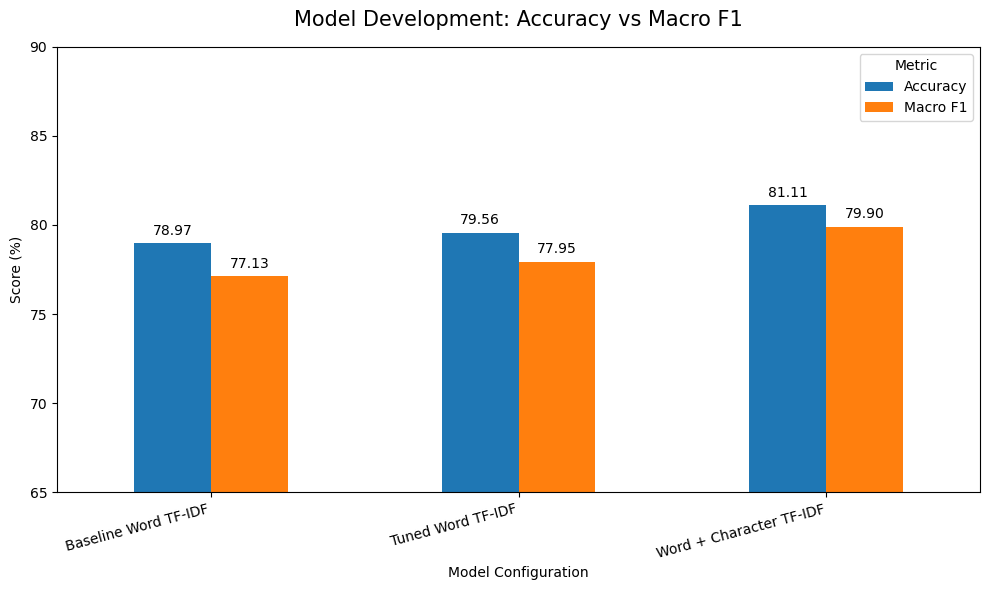

In [15]:
ax = model_comparison_display.plot(
    x="Model Configuration",
    y=["Accuracy", "Macro F1"],
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Model Development: Accuracy vs Macro F1",
    fontsize=15,
    pad=15
)

plt.xlabel("Model Configuration")
plt.ylabel("Score (%)")

# Give enough space for the bars and labels
plt.ylim(65, 90)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.legend(title="Metric")

# Add values above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4,
        fontsize=10
    )

plt.tight_layout()
plt.show()

## 14. Train the Final Model

After model selection, the best word-level and character-level TF-IDF
configurations are fitted using the complete training dataset.

The selected Logistic Regression C value is also used.

The held-out test set remains untouched until final evaluation.

In [16]:
# -----------------------------------
# Final Word TF-IDF
# -----------------------------------

final_word_tfidf = TfidfVectorizer(
    max_features=int(best_tfidf["max_features"]),
    ngram_range=best_tfidf["ngram_range"],
    sublinear_tf=best_tfidf["sublinear_tf"]
)

X_train_word_final = final_word_tfidf.fit_transform(X_train)
X_test_word_final = final_word_tfidf.transform(X_test)


# -----------------------------------
# Final Character TF-IDF
# -----------------------------------

final_char_tfidf = TfidfVectorizer(
    analyzer="char",
    max_features=30000,
    ngram_range=(3, 5),
    sublinear_tf=True
)

X_train_char_final = final_char_tfidf.fit_transform(X_train)
X_test_char_final = final_char_tfidf.transform(X_test)


# -----------------------------------
# Combine features
# -----------------------------------

X_train_combined_final = hstack([
    X_train_word_final,
    X_train_char_final
])

X_test_combined_final = hstack([
    X_test_word_final,
    X_test_char_final
])

print("Word features:", X_train_word_final.shape)
print("Character features:", X_train_char_final.shape)
print("Combined training features:", X_train_combined_final.shape)
print("Combined test features:", X_test_combined_final.shape)

Word features: (49612, 30000)
Character features: (49612, 30000)
Combined training features: (49612, 60000)
Combined test features: (992, 60000)


## 15. Train the Final Logistic Regression Model

The final model uses the selected C value from the validation experiment.

In [17]:
final_combined_model = LogisticRegression(
    C=best_C,
    max_iter=2000
)

final_combined_model.fit(
    X_train_combined_final,
    y_train
)

print("Final word + character model trained successfully.")

Final word + character model trained successfully.


## 16. Generate Final Test Predictions

The held-out test set is evaluated only after all model decisions have been
completed.

In [18]:
y_pred_combined = final_combined_model.predict(
    X_test_combined_final
)

print("Final predictions generated.")
print("Number of predictions:", len(y_pred_combined))

Final predictions generated.
Number of predictions: 992


## 17. Final Evaluation on the Held-Out Test Set

The final model is evaluated using:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1
- Per-class precision, recall, and F1

The test set is balanced, with equal representation of the four classes.
Therefore, Macro F1 is particularly useful for summarizing performance
across categories.

In [19]:
final_accuracy = accuracy_score(
    y_test,
    y_pred_combined
)

final_precision = precision_score(
    y_test,
    y_pred_combined,
    average="macro"
)

final_recall = recall_score(
    y_test,
    y_pred_combined,
    average="macro"
)

final_macro_f1 = f1_score(
    y_test,
    y_pred_combined,
    average="macro"
)

print(f"Final Accuracy:        {final_accuracy:.4f} "
      f"({final_accuracy * 100:.2f}%)")

print(f"Final Macro Precision: {final_precision:.4f} "
      f"({final_precision * 100:.2f}%)")

print(f"Final Macro Recall:    {final_recall:.4f} "
      f"({final_recall * 100:.2f}%)")

print(f"Final Macro F1:        {final_macro_f1:.4f} "
      f"({final_macro_f1 * 100:.2f}%)")

Final Accuracy:        0.8165 (81.65%)
Final Macro Precision: 0.8182 (81.82%)
Final Macro Recall:    0.8165 (81.65%)
Final Macro F1:        0.8124 (81.24%)


## 18. Per-Class Evaluation

The classification report provides precision, recall, and F1-score for
each mental-health category.

In [20]:
final_report = classification_report(
    y_test,
    y_pred_combined,
    output_dict=True
)

final_report_df = pd.DataFrame(final_report).transpose()

display(
    final_report_df.round(3)
)

,precision,recall,f1-score,support
Anxiety,0.883,0.730,0.799,248.000
Depression,0.764,0.665,0.711,248.000
Normal,0.801,0.956,0.871,248.000
Suicidal,0.825,0.915,0.868,248.000
accuracy,0.817,0.817,0.817,0.817
macro avg,0.818,0.817,0.812,992.000
weighted avg,0.818,0.817,0.812,992.000


## 19. Per-Class F1-Score

The following chart shows the final F1-score for each category.

This helps identify which categories are classified more accurately and
which categories may require further improvement.

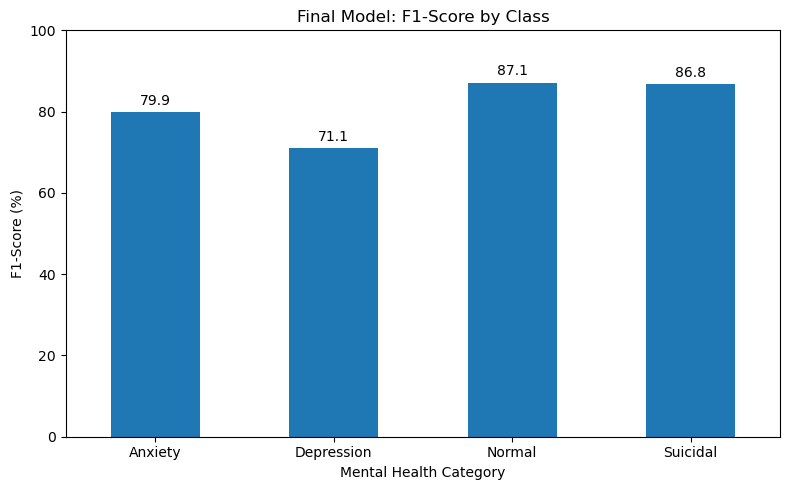

In [21]:
class_names = [
    "Anxiety",
    "Depression",
    "Normal",
    "Suicidal"
]

class_f1 = (
    final_report_df
    .loc[class_names, "f1-score"]
    * 100
)

ax = class_f1.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Final Model: F1-Score by Class")
plt.xlabel("Mental Health Category")
plt.ylabel("F1-Score (%)")
plt.ylim(0, 100)

plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=3
    )

plt.tight_layout()
plt.show()

## 20. Confusion Matrix

The confusion matrix shows how many examples from each actual category were
classified into each predicted category.

In [22]:
cm_combined = confusion_matrix(
    y_test,
    y_pred_combined,
    labels=class_names
)

cm_df = pd.DataFrame(
    cm_combined,
    index=class_names,
    columns=class_names
)

display(cm_df)

,Anxiety,Depression,Normal,Suicidal
Anxiety,181,33,26,8
Depression,21,165,26,36
Normal,2,5,237,4
Suicidal,1,13,7,227


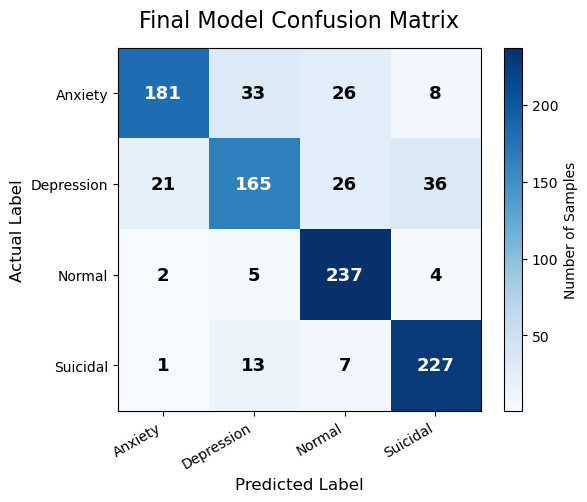

In [23]:
plt.figure(figsize=(6, 5))

plt.imshow(
    cm_combined,
    cmap="Blues"
)

plt.title(
    "Final Model Confusion Matrix",
    fontsize=16,
    pad=15
)

plt.xlabel(
    "Predicted Label",
    fontsize=12
)

plt.ylabel(
    "Actual Label",
    fontsize=12
)

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=30,
    ha="right"
)

plt.yticks(
    range(len(class_names)),
    class_names
)

plt.colorbar(
    label="Number of Samples"
)

# Add numbers with readable text color
threshold = cm_combined.max() / 2

for i in range(len(class_names)):
    for j in range(len(class_names)):

        text_color = (
            "white"
            if cm_combined[i, j] > threshold
            else "black"
        )

        plt.text(
            j,
            i,
            cm_combined[i, j],
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold",
            color=text_color
        )

plt.tight_layout()
plt.show()

## 21. Final Results Summary

The final Word + Character TF-IDF model achieved strong overall performance
on the balanced held-out test dataset.

The primary result was a Macro F1-score above 80%, indicating good overall
performance across the four categories.

Although Anxiety, Normal, and Suicidal achieved relatively strong F1-scores,
Depression had the lowest F1-score. This indicates that distinguishing
Depression from other mental-health categories remains a challenge.

The model is intended for educational and research purposes and should not
be used as a clinical diagnostic system.

In [24]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Score": [
        final_accuracy,
        final_precision,
        final_recall,
        final_macro_f1
    ]
})

final_results["Score (%)"] = (
    final_results["Score"] * 100
).round(2)

display(final_results)

,Metric,Score,Score (%)
0,Accuracy,0.816532,81.65
1,Macro Precision,0.818236,81.82
2,Macro Recall,0.816532,81.65
3,Macro F1,0.812429,81.24


### Interactive 3D Visualization of the Classification Space

The final model represents each text using a high-dimensional combination of word-level and character-level TF-IDF features. Because this feature space contains thousands of dimensions, it cannot be visualized directly. **Truncated SVD** is used to reduce the feature space to three dimensions for visualization.

Each point represents one text sample from the held-out test set. The **color indicates the actual category**, while the **marker shape indicates whether the model classified the text correctly**. The interactive Plotly visualization can be rotated and zoomed to explore the distribution of the four categories.

This visualization provides an intuitive view of the classification task, while the final accuracy, Macro F1-score, classification report, and confusion matrix provide the quantitative evaluation of model performance.

In [25]:
!pip install plotly

In [26]:
import pandas as pd
import plotly.express as px
from sklearn.decomposition import TruncatedSVD

# ---------------------------------------------------------
# Reduce the high-dimensional TF-IDF feature space to 3D
# ---------------------------------------------------------

svd = TruncatedSVD(
    n_components=3,
    random_state=42
)

X_test_3d = svd.fit_transform(X_test_combined_final)

print("Original feature dimensions:", X_test_combined_final.shape[1])
print("3D feature dimensions:", X_test_3d.shape)
print(
    f"Variance represented by 3 components: "
    f"{svd.explained_variance_ratio_.sum() * 100:.2f}%"
)

# ---------------------------------------------------------
# Create a DataFrame for the interactive visualization
# ---------------------------------------------------------

plot_df = pd.DataFrame({
    "Component 1": X_test_3d[:, 0],
    "Component 2": X_test_3d[:, 1],
    "Component 3": X_test_3d[:, 2],
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred_combined
})

# Check whether prediction is correct
plot_df["Correct"] = (
    plot_df["Actual"] == plot_df["Predicted"]
)

# Create useful hover information
plot_df["Result"] = plot_df["Correct"].map({
    True: "Correct",
    False: "Incorrect"
})

# ---------------------------------------------------------
# Interactive 3D plot
# ---------------------------------------------------------

fig = px.scatter_3d(
    plot_df,
    x="Component 1",
    y="Component 2",
    z="Component 3",
    color="Actual",
    symbol="Correct",
    hover_data={
        "Actual": True,
        "Predicted": True,
        "Result": True,
        "Component 1": False,
        "Component 2": False,
        "Component 3": False
    },
    title="Interactive 3D View of Mental-Health Text Classification",
    opacity=0.75
)

fig.update_traces(
    marker=dict(
        size=5
    )
)

fig.update_layout(
    height=750,
    legend_title="Actual Category"
)

fig.show()

Original feature dimensions: 60000
3D feature dimensions: (992, 3)
Variance represented by 3 components: 2.07%


In [27]:
import numpy as np
import imageio.v2 as imageio
from pathlib import Path

# Folder for temporary frames
frame_dir = Path("3d_frames")
frame_dir.mkdir(exist_ok=True)

frames = []

# Number of rotation frames
num_frames = 36

for i in range(num_frames):

    angle = 2 * np.pi * i / num_frames

    camera = dict(
        eye=dict(
            x=1.8 * np.cos(angle),
            y=1.8 * np.sin(angle),
            z=1.2
        )
    )

    fig.update_layout(
        scene_camera=camera,
        width=1100,
        height=650
    )

    frame_path = frame_dir / f"frame_{i:03d}.png"

    fig.write_image(str(frame_path))

    frames.append(imageio.imread(frame_path))


# Create GIF
gif_path = "mental_health_3d_rotation.gif"

imageio.mimsave(
    gif_path,
    frames,
    duration=0.45,
    loop=0
)

print("GIF created:", gif_path)

GIF created: mental_health_3d_rotation.gif


In [28]:
# AFTER final_word_tfidf, final_char_tfidf, and final_combined_model have been fitted.

import joblib

joblib.dump(
    {
        "word_tfidf": final_word_tfidf,
        "char_tfidf": final_char_tfidf,
        "model": final_combined_model,
    },
    "mind_sorts_model.joblib",
)

print("Model saved successfully!")


Model saved successfully!
